# <font style="color:black">Image Processing Basics</font>

Halaman ini akan membantu Anda mempelajari topik dasar-dasar pengolahan citra digital menggunakan library OpenCV. Pada halaman ini akan dipelajari:

* Membaca citra
* Mengubah citra ke citra grayscale
* Binerisasi citra

##  <font style="color:black">Import Libraries</font>

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve

from IPython.display import Image

%matplotlib inline

In [ ]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

URL = r"https://www.dropbox.com/s/rys6f1vprily2bg/opencv_bootcamp_assets_NB1.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), f"opencv_bootcamp_assets_NB2.zip")

# Download if assest ZIP does not exists.
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

# <font style="color:black">Membaca citra menggunakan OpenCV</font>

OpenCV dapat digunakan untuk membaca beberapa format citra (JPG, PNG, dan lain-lain). Fungsi  **`cv2.imread()`** digunakan untuk membaca citra dan memiliki sintaks sebagai berikut:

``` python
citra = cv2.imread( nama_file[, flags] )
```

`citra`: adalah hasil pembacaan citra jika berhasil dalam proses membaca citra tsb. Jika tidak sukses maka `citra` berisi `None`. Cek kembali apakah `nama_file` yang dibaca salah penulisan atau rusak.

Fungsi `imread` memiliki 1 argumen wajib `nama_file` dan 1 argumen opsional `flags`:


1. `nama_file`: dapat berupa lokasi  **absolut** atau lokasi **relatif**.

2. `Flags`:    Opsi ini memiliki nilai default `cv2.IMREAD_COLOR` atau `1` yang membaca citra sebagai citra berwarna.

Beberapa opsi nilai `flags` sebagai berikut.

**Flags**
1. **`cv2.IMREAD_GRAYSCALE`** atau **`0`**: Membaca citra sebagai citra abu-abu  (grayscale)
2. **`cv2.IMREAD_COLOR`** atau **`1`**: Membaca citra sebagai citra berwarna.
3. **`cv2.IMREAD_UNCHANGED`** atau **`-1`**: Membaca citra termasuk kanal alpha (biasa untuk transparansi).


### <font color="green">Link Dokumentasi OpenCV</font>

1. **`Imread`**:  <a href="https://docs.opencv.org/4.5.1/d4/da8/group__imgcodecs.html#ga288b8b3da0892bd651fce07b3bbd3a56" target="_blank">Documentation link</a>

2. **`ImreadModes`**: <a href="https://docs.opencv.org/4.5.1/d8/d6a/group__imgcodecs__flags.html#ga61d9b0126a3e57d9277ac48327799c80" target="_blank">Documentation link</a>


In [ ]:
# Membaca citra sebagai citra grayscale.
cb_img = cv2.imread("checkerboard_18x18.png", 0)

# Tampilkan data citra (nilai-nilai piksel), yang merupakan elemen array 2D.
# Setiap nilai piksel berukuran 8-bit [0,255]
print(cb_img)

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

## Menampilkan atribut-atribut citra

In [ ]:
# tampilkan ukuran citra
print("Ukuran citra (Tinggi, Lebar):", cb_img.shape)

# tampilkan tipe data citra
print("Tipe data citra:", cb_img.dtype)

Ukuran citra (Tinggi, Lebar): (18, 18)
Tipe data citra: uint8


## Menampilkan Citra menggunakan Matplotlib

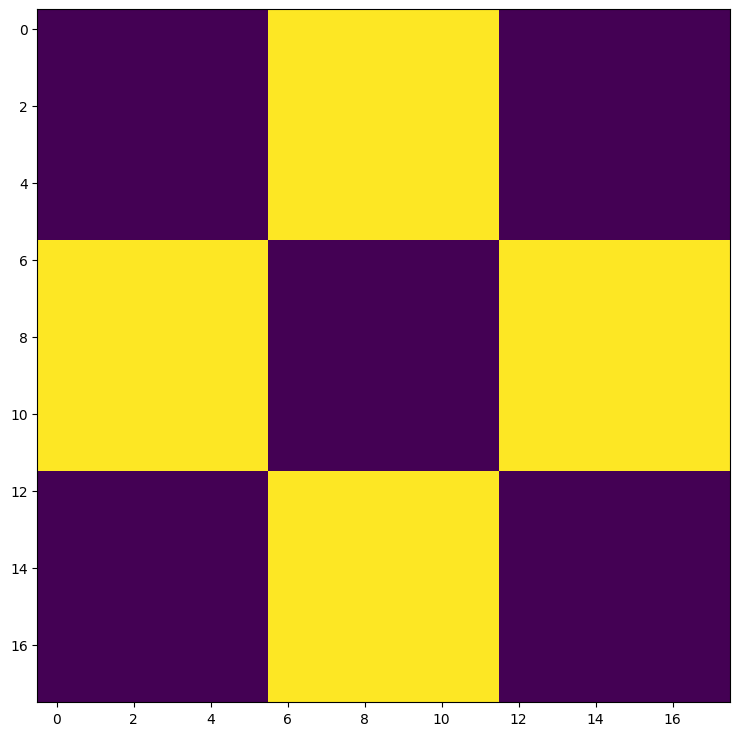

In [ ]:
# Tampilkan citra.
plt.imshow(cb_img)

### Mengapa Berwarna?

Meski citra dibaca dalam mode citra grayscale, dengan perintah `imshow()` citra tidak ditampilkan dengan mode grayscale. Pustaka matplotlib menggunakan peta warna yang berbeda sehingga memungkinkan peta warna gray scale tidak diset.

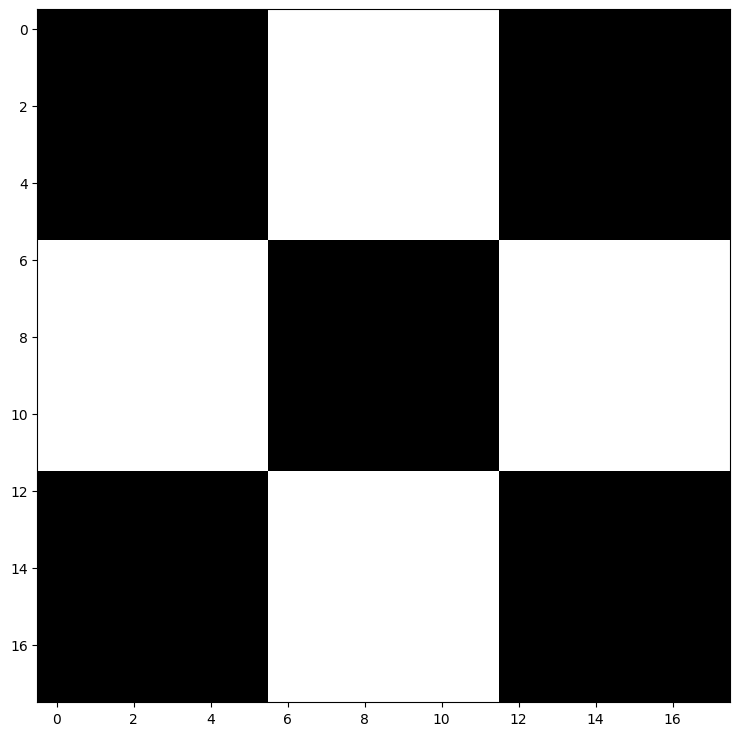

In [ ]:
# Mengatur peta warna menjadi grayscale agar tampil sesuai yang diinginkan.
plt.imshow(cb_img, cmap="gray")

## Contoh 2

[[110 108 112 ... 185 172 157]
 [107 108 113 ... 168 160 157]
 [107 110 115 ... 158 149 157]
 ...
 [ 49  48  49 ...  44  43  47]
 [ 49  48  47 ...  40  41  39]
 [ 50  48  46 ...  37  42  35]]


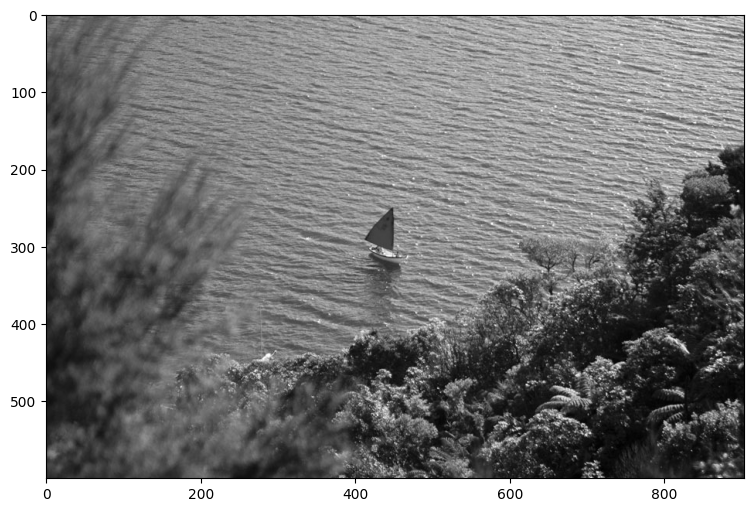

In [ ]:
# Baca citra dalam mode grayscale.
cb_img_fuzzy = cv2.imread("New_Zealand_Boat.jpg", 0)

# Tampilkan data citra
print(cb_img_fuzzy)

# Tampilkan citra.
plt.imshow(cb_img_fuzzy, cmap="gray")

## Baca dan tampilkan citra berwarna
Cek parameter-parameter dan dimensi citra berwarna.

In [ ]:
# Baca citra berwarna
img = cv2.imread("New_Zealand_Boat.jpg", 1)

# tampilkan ukuran citra
print("Ukuran citra (Tinggi, Lebar, Kanal):", img.shape)

# tampilkan tipe data citra
print("Tipe data citra:", img.dtype)

Ukuran citra (Tinggi, Lebar, Kanal): (600, 903, 3)
Tipe data citra: uint8


## Tampilkan Citranya

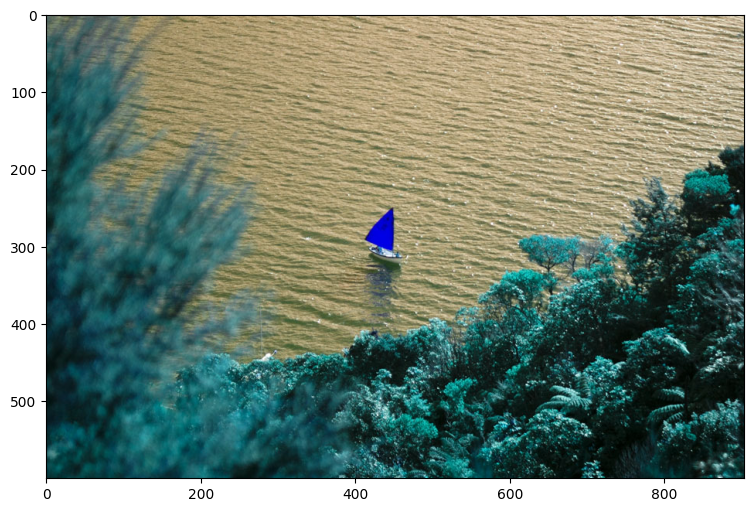

In [ ]:
plt.imshow(img)
#  Kira-kira apa yang terjadi?

Warna yang ditampilkan di atas berbeda dengan citra yang sebenarnya. Hal ini karena matplotlib membaca format citra RGB sedangkan OpenCV menyimpan citra dalam format BGR. Sehingga untuk menampilkan dengan tepat perlu dibalik urutan kanal citranya.

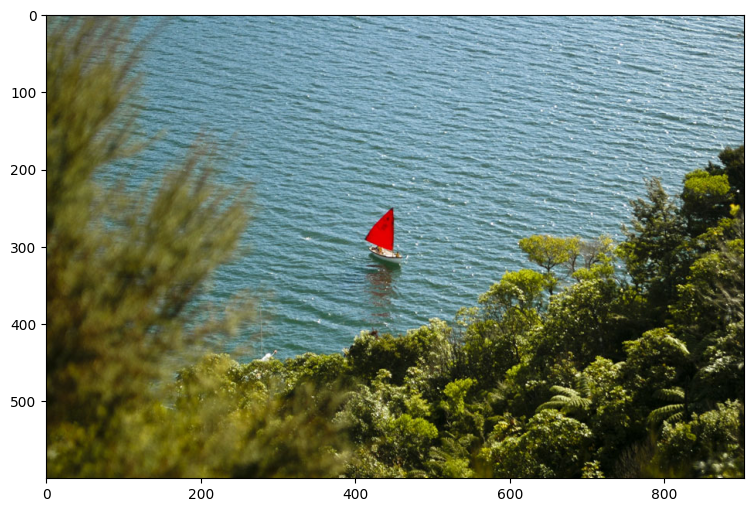

In [ ]:
img_channels_reversed = img[:, :, ::-1]
plt.imshow(img_channels_reversed)

## Memecah dan Menggabung Kanal Warna


* **`cv2.split()`** Memecah arah multi-kanal menjadi beberapa array kanal tunggal.

* **`cv2.merge()`** Menggabung beberapa array menjadi sebuah array multi-kanal. Semua matriks input harus berukuran sama.

### <font style="color:rgb(8,133,37)">Dokumentasi OpenCV</font>

<a href="https://docs.opencv.org/4.5.1/d2/de8/group__core__array.html#ga0547c7fed86152d7e9d0096029c8518a" target="_blank">Tautan Dokumentasi</a>

Text(0.5, 1.0, 'Merged Output')

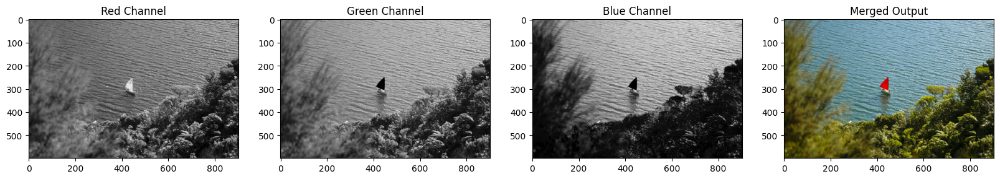

In [ ]:
# Memecah citra menjadi komponen-komponen B,G,R
img_NZ_bgr = cv2.imread("New_Zealand_Boat.jpg", cv2.IMREAD_COLOR)
b, g, r = cv2.split(img_NZ_bgr)

# Tampilkan masing-masing komponen warna
plt.figure(figsize=[20, 5])

plt.subplot(141);plt.imshow(r, cmap="gray");plt.title("Red Channel")
plt.subplot(142);plt.imshow(g, cmap="gray");plt.title("Green Channel")
plt.subplot(143);plt.imshow(b, cmap="gray");plt.title("Blue Channel")

# Gabungkan kanal-kanal individu menjadi sebuah citra BGR
imgMerged = cv2.merge((b, g, r))
# Show the merged output
plt.subplot(144)
plt.imshow(imgMerged[:, :, ::-1])
plt.title("Merged Output")

## Menyimpan Citra

Menyimpan citra di OpenCV menggunakan fungsi **`cv2.imwrite()`** dengan argumen nama file dan objek citra.

``` python
cv2.imwrite( filename, img[, params] )
```

### <font style="color:rgb(8,133,37)">Dokumentasi OpenCV</font>

1. **`Imwrite`**: <a href="https://docs.opencv.org/4.5.1/d4/da8/group__imgcodecs.html#gabbc7ef1aa2edfaa87772f1202d67e0ce" target="_blank">Documentation link</a>

2. **`ImwriteFlags`**: <a href="https://docs.opencv.org/4.5.1/d8/d6a/group__imgcodecs__flags.html#ga292d81be8d76901bff7988d18d2b42ac" target="_blank">Documentation link</a>

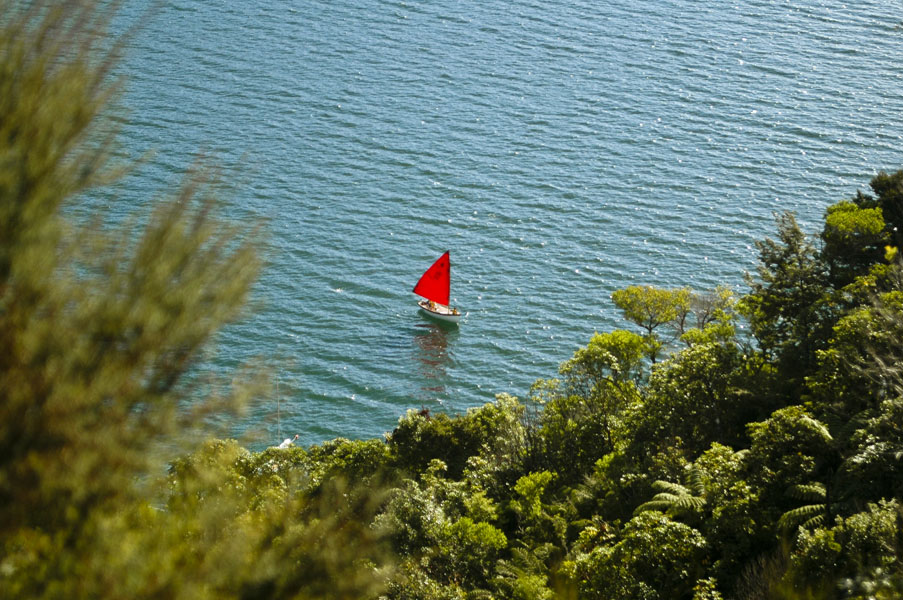

In [ ]:
# menyimpan citra
cv2.imwrite("New_Zealand_Boat_SAVED.png", img_NZ_bgr)

Image(filename='New_Zealand_Boat_SAVED.png')

In [ ]:
# membaca citra dalam mode berwarna
img_NZ_bgr = cv2.imread("New_Zealand_Boat_SAVED.png", cv2.IMREAD_COLOR)
print("Ukuran img_NZ_bgr (Tinggi, Lebar, Kanal):", img_NZ_bgr.shape)

# membaca citra dalam mode Grayscale
img_NZ_gry = cv2.imread("New_Zealand_Boat_SAVED.png", cv2.IMREAD_GRAYSCALE)
print("Ukuran img_NZ_gry (Tinggi, Lebar):", img_NZ_gry.shape)

Ukuran img_NZ_bgr (Tinggi, Lebar, Kanal): (600, 903, 3)
Ukuran img_NZ_gry (Tinggi, Lebar): (600, 903)


Section 2

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

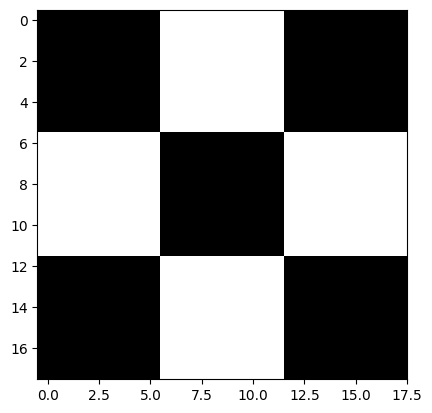

In [ ]:
# membaca citra dalam mode Grayscale
cb_img = cv2.imread("checkerboard_18x18.png", 0)

# set color map ke gray scale
plt.imshow(cb_img, cmap="gray")
print(cb_img)

## Mengakses piksel-piksel secara individu

Untuk mengakses piksel dalam sebuah matriks numpy, gunakan notasi matriks seperti matrix[r,c], dimana r adalah nomor baris dan c adalah nomor kolom.

Misalnya untuk mengakses piksel pertama, gunakan matrix[0,0]. Berikut contoh yang menampilkan sebuah piksel hitam dari pojok kiri atas dan satu piksel putih dari arah tengah-atas.

In [ ]:
# menampilkan isi piksel pertama dari kotak hitam pertama
print(cb_img[0, 0])
# menampilkan isi piksel putih pertama dari kotak sebelah kanan dari kotak hitam pertama
print(cb_img[0, 6])

0
255


## <font style="color:black">Modifikasi Piksel Citra</font>
Berikut contoh mengubah isi piksel citra

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 200 200   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 200 200   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

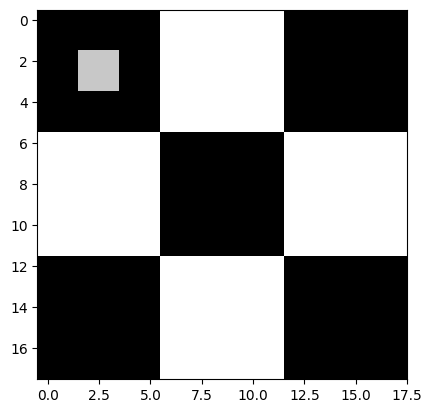

In [ ]:
cb_img_copy = cb_img.copy()
cb_img_copy[2, 2] = 200
cb_img_copy[2, 3] = 200
cb_img_copy[3, 2] = 200
cb_img_copy[3, 3] = 200

# Cara lain untuk ke-4 baris kode diatas:
# cb_img_copy[2:3,2:3] = 200

plt.imshow(cb_img_copy, cmap="gray")
print(cb_img_copy)

# Memotong Citra

Dapat dilakukan dengan memilih piksel tertentu pada sebuah citra.

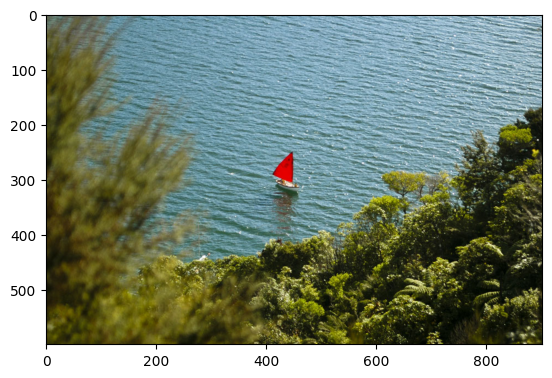

In [ ]:
img_NZ_bgr = cv2.imread("New_Zealand_Boat.jpg", cv2.IMREAD_COLOR)
img_NZ_rgb = img_NZ_bgr[:, :, ::-1]

plt.imshow(img_NZ_rgb)

### <font color="green">Potong citra dengan menyisakan bagian tengah citra</font>

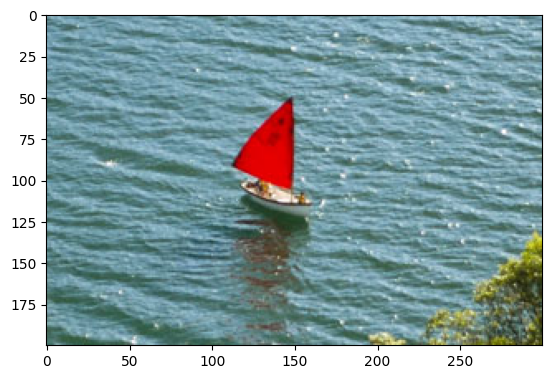

In [ ]:
cropped_region = img_NZ_rgb[200:400, 300:600]
plt.imshow(cropped_region)

# Mengubah Ukuran Citra

Fungsi **`resize`** mengubah ukuran citra `src` ke ukuran yang dispesifikasikan.

### <font style="color:rgb(8,133,37)">Sintaks Fungsi </font>

``` python
dst = resize( src, dsize[, dst[, fx[, fy[, interpolation]]]] )
```

Fungsi tsb memiliki **2 parameter wajib**:
    
1. `src`:	citra input

2. `dsize`: ukutan citra output

Parameter opsional yang sering digunakan antara lain:

1. `fx`: Faktor skala sepanjang sumbu horizontal; jika bernilai 0, maka nilainya dihitung dengan (𝚍𝚘𝚞𝚋𝚕𝚎)𝚍𝚜𝚒𝚣𝚎.𝚠𝚒𝚍𝚝𝚑/𝚜𝚛𝚌.𝚌𝚘𝚕𝚜

2. `fy`: Faktor skala sepanjang sumbu vertikal; jika bernilai 0, maka nilainya dihitung dengan (𝚍𝚘𝚞𝚋𝚕𝚎)𝚍𝚜𝚒𝚣𝚎.𝚑𝚎𝚒𝚐𝚑𝚝/𝚜𝚛𝚌.𝚛𝚘𝚠𝚜


### <font style="color:rgb(8,133,37)">Dokumentasi OpenCV</font>

**`resize()`**: <a href="https://docs.opencv.org/4.5.0/da/d54/group__imgproc__transform.html#ga47a974309e9102f5f08231edc7e7529d" target="_blank">Documentation link</a>

### <font color="green"> Cara 1: Spesifikasi Faktor Skala menggunakan fx dan fy


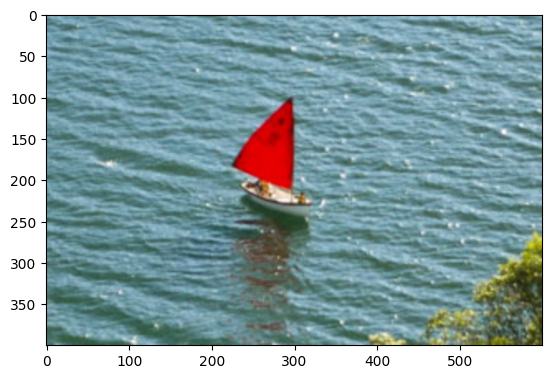

In [ ]:
resized_cropped_region_2x = cv2.resize(cropped_region, None, fx=2, fy=2)
plt.imshow(resized_cropped_region_2x)

### <font color="green">Cara 2: Spesifikasi Faktor Skala menggunakan ukuran citra output</font>

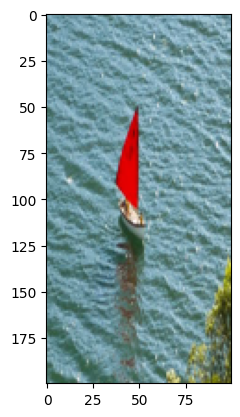

In [ ]:
desired_width = 100
desired_height = 200
dim = (desired_width, desired_height)

resized_cropped_region = cv2.resize(cropped_region, dsize=dim, interpolation=cv2.INTER_AREA)
plt.imshow(resized_cropped_region)

### <font color="green">Mengubah ukuran dengan mempertahankan aspek rasio </font>

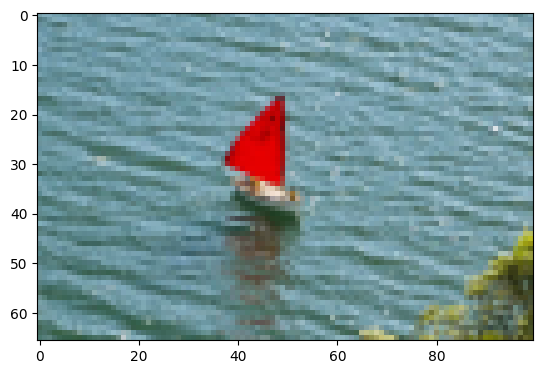

In [ ]:
desired_width = 100
aspect_ratio = desired_width / cropped_region.shape[1]
desired_height = int(cropped_region.shape[0] * aspect_ratio)
dim = (desired_width, desired_height)

resized_cropped_region = cv2.resize(cropped_region, dsize=dim, interpolation=cv2.INTER_AREA)
plt.imshow(resized_cropped_region)

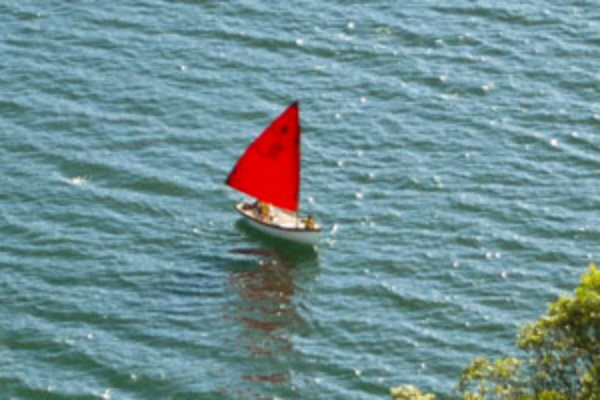

In [ ]:
# Swap channel order
resized_cropped_region_2x = resized_cropped_region_2x[:, :, ::-1]

# Save resized image to disk
cv2.imwrite("resized_cropped_region_2x.png", resized_cropped_region_2x)

# Display the cropped and resized image
Image(filename="resized_cropped_region_2x.png")

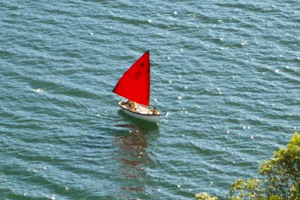

In [ ]:
# Swap channel order
cropped_region = cropped_region[:, :, ::-1]

# Save cropped 'region'
cv2.imwrite("cropped_region.png", cropped_region)

# Display the cropped and resized image
Image(filename="cropped_region.png")

# Membalik Citra


Fungsi **`flip`** membalik array dengan tiga cara:

``` python
dst = cv.flip( src, flipCode )
```

`dst`: array output dengan ukuran dan tipe yang sama dengan src.

Fungsi tsb memiliki **2 parameter wajib**:
    
1. `src`:	citra input
2. `flipCode`: sebuah tanda bagaimana membalik array; 0 artinya membalik citra terhadap sumbu x, nilai positif (misalnya, 1) artinya membalik citra terhadap sumbu y. Nilai negatif (misalnya, -1) artinya membalik citra terhadap kedua sumbu x dan y.


### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

**`flip`**: <a href="https://docs.opencv.org/4.5.0/d2/de8/group__core__array.html#gaca7be533e3dac7feb70fc60635adf441" target="_blank">Documentation link</a>

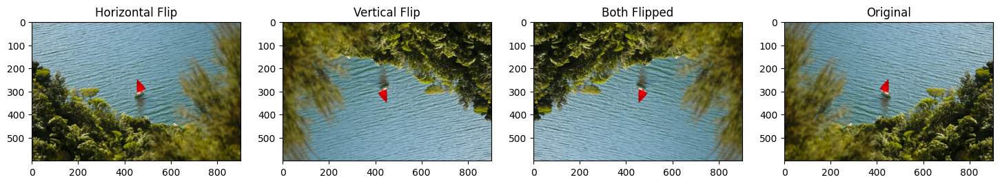

In [ ]:
img_NZ_rgb_flipped_horz = cv2.flip(img_NZ_rgb, 1)
img_NZ_rgb_flipped_vert = cv2.flip(img_NZ_rgb, 0)
img_NZ_rgb_flipped_both = cv2.flip(img_NZ_rgb, -1)

# Show the images
plt.figure(figsize=(18, 5))
plt.subplot(141);plt.imshow(img_NZ_rgb_flipped_horz);plt.title("Horizontal Flip");
plt.subplot(142);plt.imshow(img_NZ_rgb_flipped_vert);plt.title("Vertical Flip");
plt.subplot(143);plt.imshow(img_NZ_rgb_flipped_both);plt.title("Both Flipped");
plt.subplot(144);plt.imshow(img_NZ_rgb);plt.title("Original");


# <font style="color:black">Menganotasi Citra</font>

Anotasi citra yang dibahas antara lain:

* Menggambar Garis
* Menggambar Lingkaran
* Menggambar segi empat
* Menambahkan teks

Anotasi citra berguna ketika kita ingin menunjukkan aplikasi komputer vision kita. Anotasi citra juga dapat digunakan selama proses pengembangan aplikasi atau debugging aplikasi yang dikembangkan. Misalnya pada aplikasi dengan data citra medis, seringkali perlu dilakukan anotasi citra pada data citra medis untuk tujuan anonimisasi data.


In [ ]:
# Import libraries
import os
import cv2
import matplotlib
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve

matplotlib.rcParams['figure.figsize'] = (9.0, 9.0)

%matplotlib inline

##  <font style="color:black">Download Assets</font>

In [ ]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

In [ ]:
URL = r"https://www.dropbox.com/s/48hboi1m4crv1tl/opencv_bootcamp_assets_NB3.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), "opencv_bootcamp_assets_NB3.zip")

# Download if assest ZIP does not exists.
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

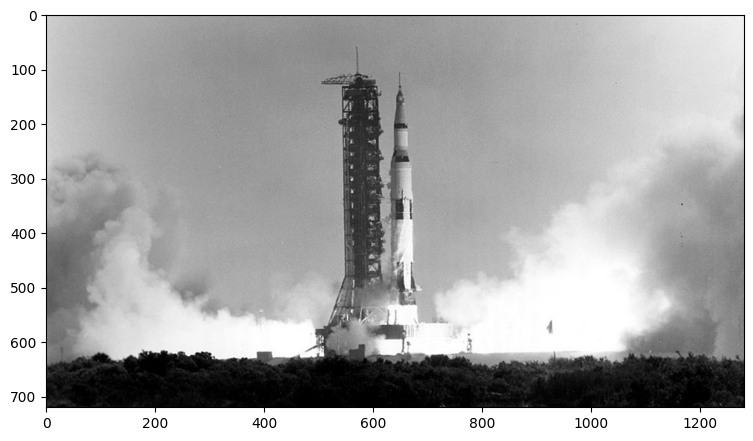

In [ ]:
# Read in an image
image = cv2.imread("Apollo_11_Launch.jpg", cv2.IMREAD_COLOR)

# Display the original image
plt.imshow(image[:, :, ::-1])

## <font style="color:black">Menggambar Garis</font>

Untuk menggambat garis pada sebuah citra, digunakan fungsi cv2.line

### <font style="color:rgb(8,133,37)">Sintaks Fungsi</font>
``` python
    img = cv2.line(img, pt1, pt2, color[, thickness[, lineType[, shift]]])
```

`img`: Citra output yang telah dianotasi.

Fungsi tsb memiliki **4 parameter wajib**:

1. `img`:   Citra yang akan digambari sebuah garis

2. `pt1`:   Titik pertama (lokasi x,y) dari segmen garis

3. `pt2`:   Titik kedua segmen garis

4. `color`: Warna garis
    
Parameter opsional lainnya antara lain:

1. `thickness`: Integer yang menspesifikasikan ketebalan garis. Nilai default adalah 1.

2. `lineType`:  Tipe garis. Nilai default adalah 8 yang artinya garis 8-connected. Umumnya cv2.LINE_AA (antialiased atau garis halus) digunakan untuk parameter lineType.
    
### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

**`line`**: <a href="https://docs.opencv.org/4.5.1/d6/d6e/group__imgproc__draw.html#ga7078a9fae8c7e7d13d24dac2520ae4a2" target="_blank">Documentation link</a>

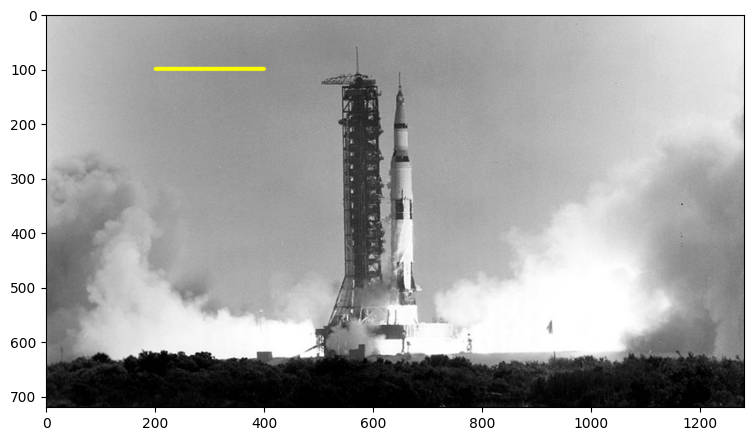

In [ ]:
imageLine = image.copy()

# Garis dimulai dari lokasi (200,100) dan berakhir pada lokasi (400,100)
# Warna garis adalah KUNING (Ingat bahwa OpenCV menggunakan format BGR)
# Ketebalan garis sebesar 5px
# Tipe garis adalah cv2.LINE_AA

cv2.line(imageLine, (200, 100), (400, 100), (0, 255, 255), thickness=5, lineType=cv2.LINE_AA);

# Tampilkan hasilnya
plt.imshow(imageLine[:,:,::-1])

## <font style="color:black">Menggambar Lingkaran</font>


Fungsi cv2.circle digunakan untuk menggambar sebuah lingkaran pada sebuah citra.

### <font style="color:rgb(8,133,37)">Sintaks Fungsi</font>
``` python
img = cv2.circle(img, center, radius, color[, thickness[, lineType[, shift]]])
```

`img`: Citra output yang telah dianotasi.

Fungsi tsb memiliki **4 parameter wajib**:

1. `img`:    Citra yang akan dianotasi dengan lingkaran

2. `center`: Pusat lingkaran

3. `radius`: Radius lingkaran

4. `color`:  Warna lingkaran
    
Parameter opsional antara lain:

1. `thickness`: Ketebalan garis lingkaran (jika bernilai positif).
Jika bernilai negatif maka lingkaran akan digambar beserta warna interior lingkaran (tidak hanya garis luar lingkaran saja).

2. `lineType`:  Tipe bingkai lingkaran, serupa dengan parameter lineType pada fungsi **cv2.line**
    
### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>
    
**`circle`**: <a href="https://docs.opencv.org/4.5.1/d6/d6e/group__imgproc__draw.html#gaf10604b069374903dbd0f0488cb43670" target="_blank">Documentation link</a>

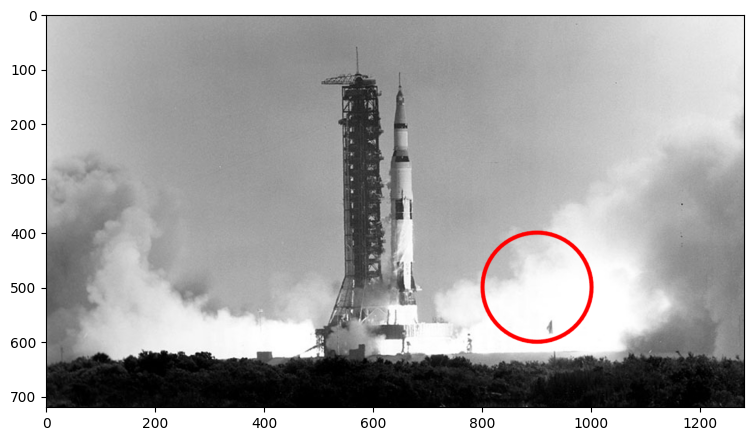

In [ ]:
# Draw a circle
imageCircle = image.copy()

cv2.circle(imageCircle, (900,500), 100, (0, 0, 255), thickness=5, lineType=cv2.LINE_AA);

# Display the image
plt.imshow(imageCircle[:,:,::-1])

## <font style="color:black">Menggambar Segi Empat</font>


Fungsi **cv2.rectangle** digunakan untuk menggambar segi empat pada sebuah citra

### <font style="color:rgb(8,133,37)">Sintaks Fungsi</font>

    img = cv2.rectangle(img, pt1, pt2, color[, thickness[, lineType[, shift]]])

`img`: Citra output yang telah dianotasi.

Fungsi tsb memiliki **4 parameter wajib**:

1. `img`: Citra yang akan dianotasi gambar segi empat.

2. `pt1`: Salah satu titik sudut segi empat, biasanya digunakan titik pojok **kiri-atas**.

3. `pt2`: Titik sudut pada segi empat yang merupakan titik diagonal lawan pt1, biasanya digunakan titik pojok **kanan-bawah**.

4. `color`: Warna segi empat
    
Parameter opsional antara lain:

1. `thickness`: Ketebalan dari garis batas luar segi empat (jika bernilai positif). Jika bernilai negatif maka segi empat yang dihasilkan akan diwarnai interiornya.

2. `lineType`: Jenis garis batas segi empat, memiliki fungsi yang sama dengan parameter lineType pada
    **cv2.line**
    
### <font style="color:rgb(8,133,37)">OpenCV Documentation Links</font>

**`rectangle`**: <a href="https://docs.opencv.org/4.5.1/d6/d6e/group__imgproc__draw.html#ga07d2f74cadcf8e305e810ce8eed13bc9" target="_blank">Documentation link</a>

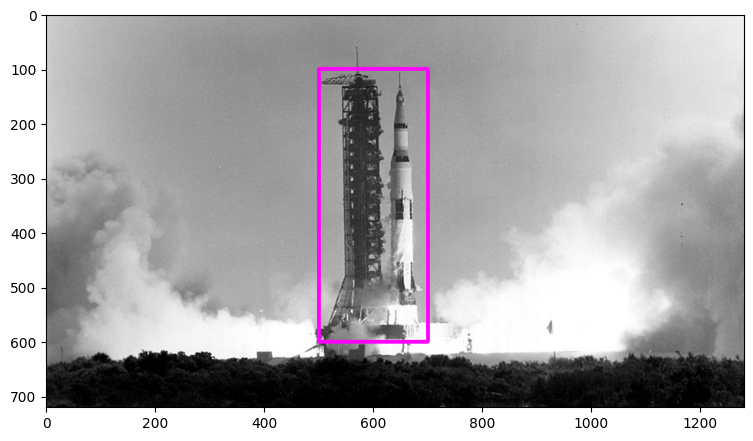

In [ ]:
# Draw a rectangle (thickness is a positive integer)
imageRectangle = image.copy()

cv2.rectangle(imageRectangle, (500, 100), (700, 600), (255, 0, 255), thickness=5, lineType=cv2.LINE_8)

# Display the image
plt.imshow(imageRectangle[:, :, ::-1])

## <font style="color:black">Menambahkan Teks</font>

Fungsi yang digunakan untuk menambahkan teks ke dalam citra adalah **cv2.putText**.

### <font style="color:rgb(8,133,37)">Sintaks Fungsi</font>

    img = cv2.putText(img, text, org, fontFace, fontScale, color[, thickness[, lineType[, bottomLeftOrigin]]])

`img`: Citra output

Fungsi  **cv2.putText** memiliki **6 parameter wajib**:

1. `img`: Citra yang akan dianotasi

2. `text`: Teks yang akan ditambahkan.

3. `org`: Pojok kiri-bawah string teks dalam citra.

4. `fontFace`: Font type

5. `fontScale`: Faktor skala font yang dikalikan dengan ukuran basis font tertentu.

6. `color`: Font color

Parameter opsional lain antara lain:

1. `thickness`: Bilangan bulat yang ketebalan garis teks, nilai default nya 1.

2. `lineType`: Tipe garis. Nilai default adalah 8 yang artinya garis 8-connected. Umumnya cv2.LINE_AA (antialiased atau garis halus) digunakan untuk parameter lineType.

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

**`putText`**: <a href="https://docs.opencv.org/4.5.1/d6/d6e/group__imgproc__draw.html#ga5126f47f883d730f633d74f07456c576" target="_blank">Documentation link</a>

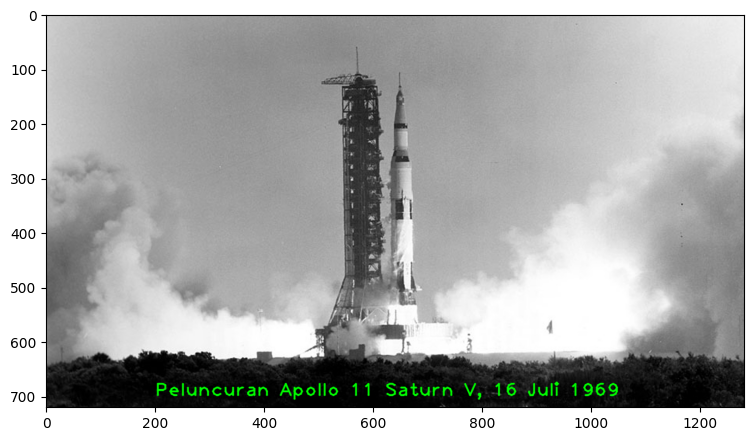

In [ ]:
imageText = image.copy()
text = "Peluncuran Apollo 11 Saturn V, 16 Juli 1969"
fontScale = 2.3
fontFace = cv2.FONT_HERSHEY_PLAIN
fontColor = (0, 255, 0)
fontThickness = 2

cv2.putText(imageText, text, (200, 700), fontFace, fontScale, fontColor, fontThickness, cv2.LINE_AA);

# Tampilkan citra setelah ditambahi teks
plt.imshow(imageText[:, :, ::-1])

# <font style="color:black">Peningkatan Kualitas Citra Menggunakan Operasi Matematis</font>
Teknik pemrosesan citra memanfaatkan operasi matematis untuk berbagai hasil yang berbeda. Beberapa antara lain:

* Operasi aritmetika seperti penjumlahan dan perkalian
* Thresholding & Masking
* Operasi Bitwise seperti OR, AND, XOR

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve

from IPython.display import Image

%matplotlib inline

##  <font style="color:black">Download Assets</font>

In [ ]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

In [ ]:
URL = r"https://www.dropbox.com/s/0oe92zziik5mwhf/opencv_bootcamp_assets_NB4.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), "opencv_bootcamp_assets_NB4.zip")

# Download if assest ZIP does not exists.
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

### <font color="green">Citra Orisinal</font>

Ukuran img_bgr (Tinggi, Lebar, Kanal): (600, 840, 3)


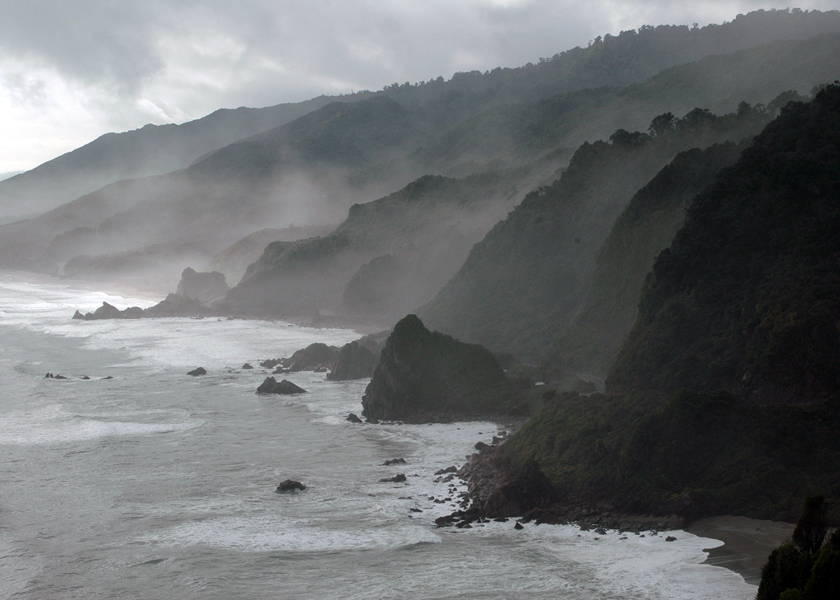

In [ ]:
img_bgr = cv2.imread("New_Zealand_Coast.jpg", cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print("Ukuran img_bgr (Tinggi, Lebar, Kanal):", img_bgr.shape)

# Tampilkan image.
Image(filename="New_Zealand_Coast.jpg")

## Penjumlahan --> Tingkat kecerahan
Operasi penjumlahan citra dapat meningkatkan atau menurunkan kecerahan citra karena nilai intensitas setiap piksel citra akan dinaikkan atau diturunkan dengan besaran yang sama. Sehingga hal ini akan meningkatkan/menurunkan kecerahan citra secara keseluruhan.

[[[50 50 50]
  [50 50 50]
  [50 50 50]
  ...
  [50 50 50]
  [50 50 50]
  [50 50 50]]

 [[50 50 50]
  [50 50 50]
  [50 50 50]
  ...
  [50 50 50]
  [50 50 50]
  [50 50 50]]

 [[50 50 50]
  [50 50 50]
  [50 50 50]
  ...
  [50 50 50]
  [50 50 50]
  [50 50 50]]

 ...

 [[50 50 50]
  [50 50 50]
  [50 50 50]
  ...
  [50 50 50]
  [50 50 50]
  [50 50 50]]

 [[50 50 50]
  [50 50 50]
  [50 50 50]
  ...
  [50 50 50]
  [50 50 50]
  [50 50 50]]

 [[50 50 50]
  [50 50 50]
  [50 50 50]
  ...
  [50 50 50]
  [50 50 50]
  [50 50 50]]]


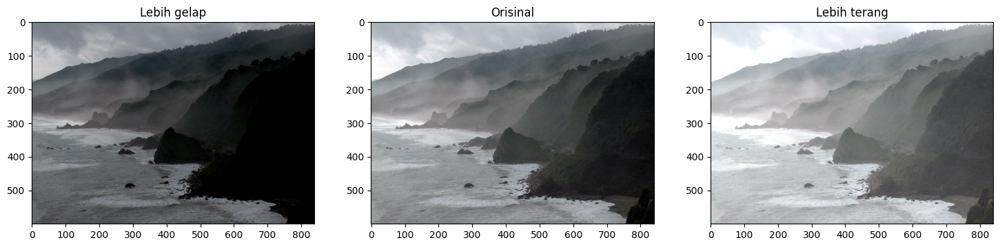

In [ ]:
matrix = np.ones(img_rgb.shape, dtype="uint8") * 50
print(matrix)

img_rgb_brighter = cv2.add(img_rgb, matrix)
img_rgb_darker   = cv2.subtract(img_rgb, matrix)


# Tampilkan semua citra sebagai berikut
plt.figure(figsize=[18, 5])
plt.subplot(131); plt.imshow(img_rgb_darker);  plt.title("Lebih gelap");
plt.subplot(132); plt.imshow(img_rgb);         plt.title("Orisinal");
plt.subplot(133); plt.imshow(img_rgb_brighter);plt.title("Lebih terang");

## Brightness Adjustment

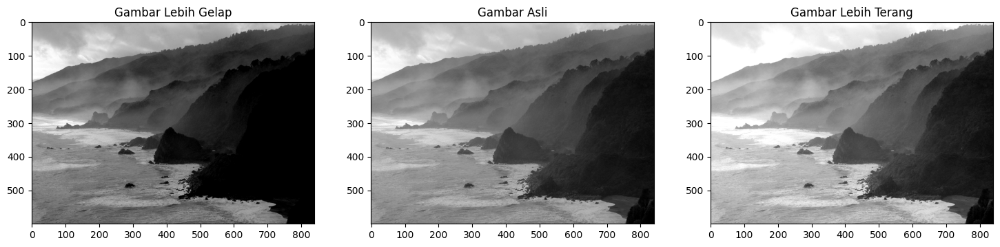

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ensure img_read is loaded from the previous example, or load it if not.
# For demonstration, we'll assume 'img_read' from the contrast stretching example is available.
# If not, uncomment and modify the line below:
img_read = cv2.imread("New_Zealand_Coast.jpg", cv2.IMREAD_GRAYSCALE)

# Define the constant value to add/subtract for brightness adjustment
# A value of 50 is used for demonstration; adjust as needed.
brightness_offset = 50

# Create a matrix of the same shape as img_read filled with the brightness_offset
# This matrix will be added/subtracted from the image.
# For addition, we ensure the image type is uint8 so cv2.add handles saturation.
matrix = np.ones(img_read.shape, dtype="uint8") * brightness_offset

# Increase brightness using cv2.add
# cv2.add handles saturation, so pixel values won't exceed 255.
img_brighter = cv2.add(img_read, matrix)

# Decrease brightness using cv2.subtract
# cv2.subtract handles saturation, so pixel values won't go below 0.
img_darker = cv2.subtract(img_read, matrix)

# Display the original, darker, and brighter images
plt.figure(figsize=[18, 5])
plt.subplot(131); plt.imshow(img_darker, cmap="gray"); plt.title("Gambar Lebih Gelap");
plt.subplot(132); plt.imshow(img_read, cmap="gray");    plt.title("Gambar Asli");
plt.subplot(133); plt.imshow(img_brighter, cmap="gray"); plt.title("Gambar Lebih Terang");
plt.show()

In this example, we apply brightness adjustments to the grayscale image. We create a constant offset value (`brightness_offset`). By adding this offset to each pixel's intensity value using `cv2.add()`, the image becomes brighter. Conversely, by subtracting the offset using `cv2.subtract()`, the image becomes darker. OpenCV's `add()` and `subtract()` functions are useful here because they automatically handle value saturation, ensuring pixel intensities remain within the valid 0-255 range for 8-bit images.

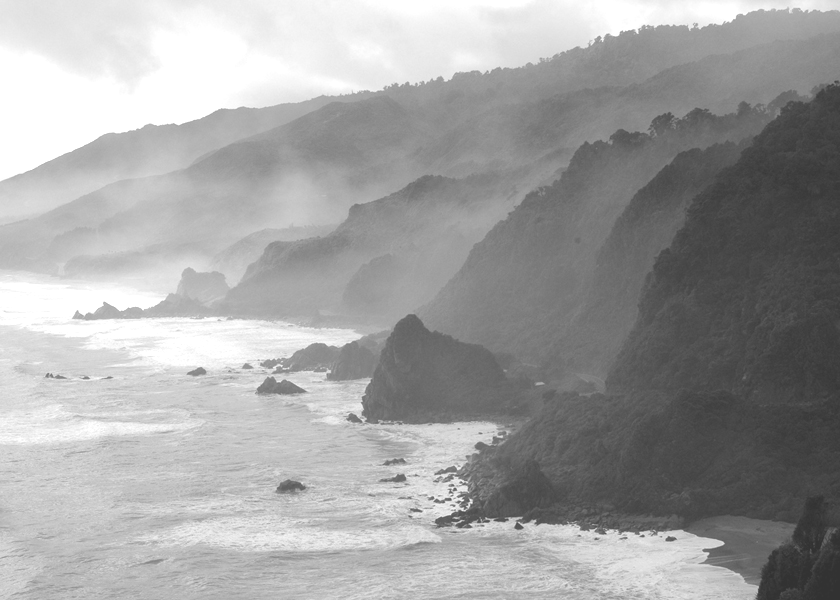

In [ ]:
# menyimpan citra darker
cv2.imwrite("New_Zealand_Coast-darker.png", img_darker)

Image(filename='New_Zealand_Coast-darker.png')

# menyimpan citra brighter
cv2.imwrite("New_Zealand_Coast-brighter.png", img_brighter)

Image(filename='New_Zealand_Coast-brighter.png')

## Perkalian --> Kekontrasan
Operasi perkalian dapat digunakan untuk meningkatkan kekontrasan dalam citra.

Kekontrasan adalah perbedaan nilai intensitas piksel dalam sebuah citra.
Perkalian nilai intensitas dengan sebuah konstanta dapat menghasilkan kekontrasan menjadi lebih tinggi atau lebih rendah (jika faktor pengalinya < 1).

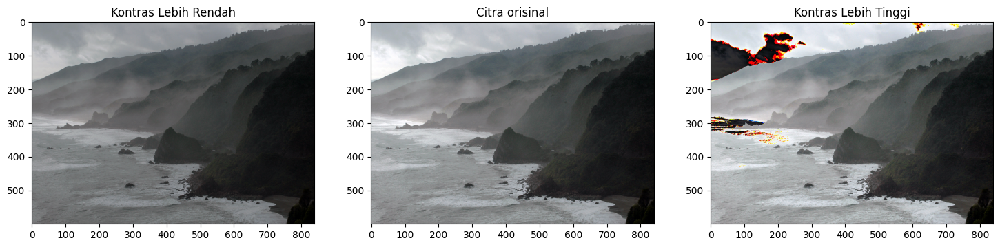

In [ ]:
matrix_low_contrast = np.ones(img_rgb.shape) * 0.8
matrix_high_contast = np.ones(img_rgb.shape) * 1.2

img_rgb_darker   = np.uint8(cv2.multiply(np.float64(img_rgb), matrix_low_contrast))
img_rgb_brighter = np.uint8(cv2.multiply(np.float64(img_rgb), matrix_high_contast))

# Tampilkan citranya
plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(img_rgb_darker);  plt.title("Kontras Lebih Rendah");
plt.subplot(132); plt.imshow(img_rgb);         plt.title("Citra orisinal");
plt.subplot(133); plt.imshow(img_rgb_brighter);plt.title("Kontras Lebih Tinggi");

### <font color="green">Analisis</font>
Setelah operasi perkalian, pada beberapa area citra terdapat warna-warna yang tidak sesuai.

Hal ini dikarenakan setelah proses perkalian, beberapa nilai piksel menjadi sangat tinggi, melebihi 255. Berikut cara untuk mengatasinya.

### <font color="green">Penanganan Overflow menggunakan np.clip</font>

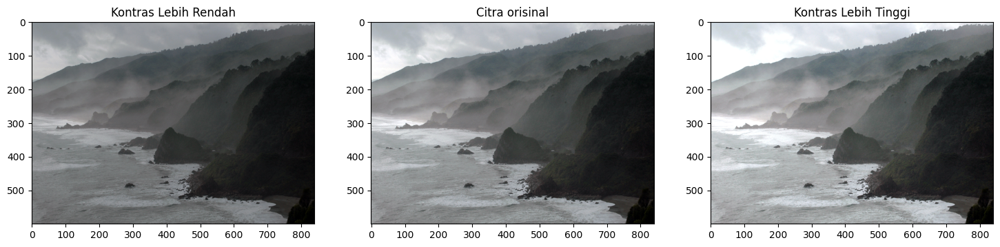

In [ ]:
matrix_low_contrast = np.ones(img_rgb.shape) * 0.8
matrix_high_contast = np.ones(img_rgb.shape) * 1.2

img_rgb_lower  = np.uint8(cv2.multiply(np.float64(img_rgb), matrix_low_contrast))
img_rgb_higher = np.uint8(np.clip(cv2.multiply(np.float64(img_rgb), matrix_high_contast), 0, 255))

# Tampilkan citranya
plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(img_rgb_lower);  plt.title("Kontras Lebih Rendah");
plt.subplot(132); plt.imshow(img_rgb);         plt.title("Citra orisinal");
plt.subplot(133); plt.imshow(img_rgb_higher);plt.title("Kontras Lebih Tinggi");

## Contrast Stretching

Before:  0 255
After:  0 255


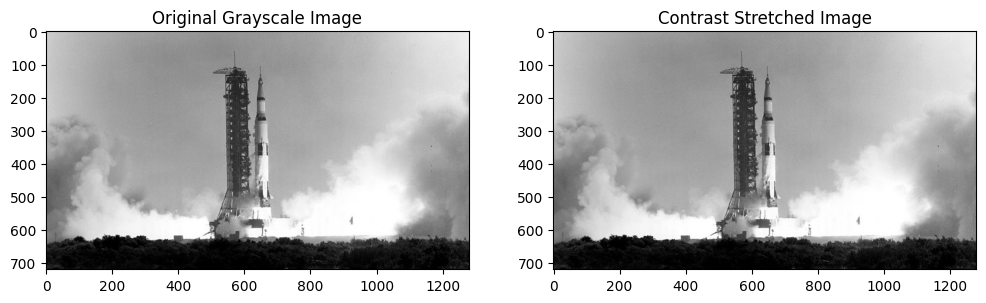

In [ ]:
from matplotlib.colors import Colormap
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load a grayscale image (using one previously loaded in the notebook)
# If 'img_read' is not available, you would load it here, e.g.,
img_read = cv2.imread("Apollo_11_Launch.jpg", cv2.IMREAD_GRAYSCALE)

# Ensure img_read is 8-bit grayscale for this example
if img_read.dtype != np.uint8:
    img_read = cv2.normalize(img_read, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Get min and max pixel values
min_val = np.min(img_read)
max_val = np.max(img_read)

# Calculate the contrast stretched image
# Formula: output_pixel = (input_pixel - min_val) * (255 / (max_val - min_val))
if max_val - min_val == 0:
    # Handle case where all pixels have the same value (e.g., solid black or white image)
    stretched_img = img_read.copy()
else:
    stretched_img = np.zeros_like(img_read, dtype=np.uint8)
    stretched_img = cv2.normalize(img_read, stretched_img, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)

# Get min and max pixel values of stretched image
min_val_s = np.min(stretched_img)
max_val_s = np.max(stretched_img)

print('Before: ', min_val, max_val)
print('After: ', min_val_s, max_val_s)

# Display the original and contrast-stretched images
plt.figure(figsize=[12, 6])
plt.subplot(121); plt.imshow(img_read, cmap="gray"); plt.title("Original Grayscale Image")
plt.subplot(122); plt.imshow(stretched_img, cmap="gray"); plt.title("Contrast Stretched Image")
plt.show()

The code first loads a grayscale image. It then finds the minimum and maximum pixel intensity values present in the image. Using these values, it applies a linear transformation to map the original intensity range `[min_val, max_val]` to the full 8-bit range `[0, 255]`. This process increases the overall contrast of the image, making details more visible.

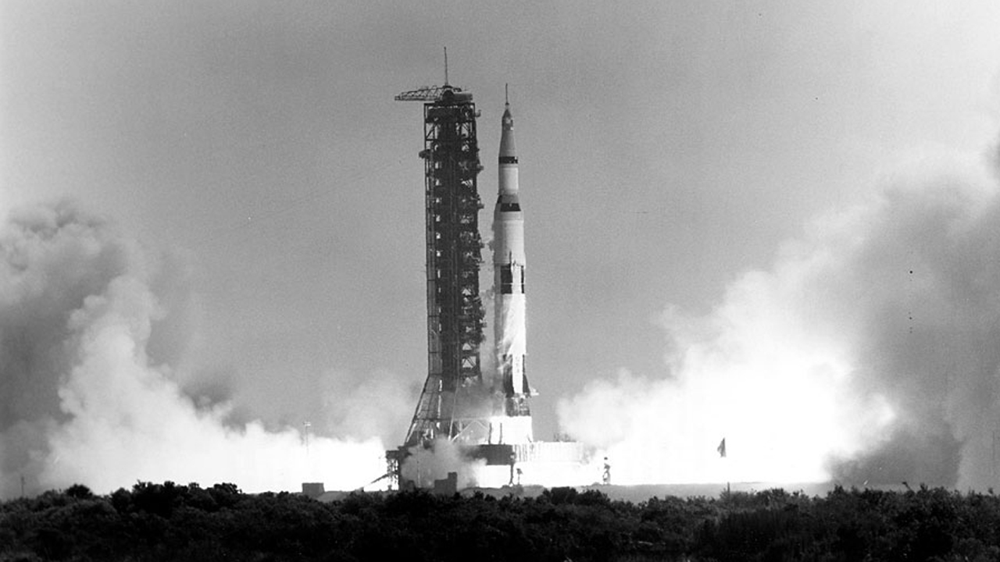

In [ ]:
# menyimpan citra
cv2.imwrite("Apollo_11_Launch_stretched.png", stretched_img)

Image(filename='Apollo_11_Launch_stretched.png')

## Operasi Bitwise

### <font style="color:rgb(8,133,37)">Sintaks Fungsi</font>

Contoh fungsi antara lain: `cv2.bitwise_and()`, `cv2.bitwise_or()`, `cv2.bitwise_xor()`, dan `cv2.bitwise_not()`

``` python
dst = cv2.bitwise_and( src1, src2[, dst[, mask]] )
```

`dst`: Array output dengan ukuran dan tipe yang sama dengan array input.

Fungsi `cv2.bitwise_and()` memiliki **2 parameter wajib**:

1. `src1`:	array input pertama atau sebuah skalar.

2. `src2`:	array input kedua atau skalar.

Argumen opsional yang penting adalah:

1. `mask`:	sebuah array 8-bit dengan kanal tunggal, yang menentukan elemen-elemen khusus pada array output yang akan diubah.


### <font style="color:rgb(8,133,37)">Dokumentasi OpenCV</font>

1. <a href="https://docs.opencv.org/4.5.1/d0/d86/tutorial_py_image_arithmetics.html" target="_blank">Operasi aritmatika pada citra</a>

2. <a href="https://docs.opencv.org/4.5.0/d2/de8/group__core__array.html#ga60b4d04b251ba5eb1392c34425497e14" target="_blank">Fungsi `cv2.bitwise_and()`</a>

(200, 499)


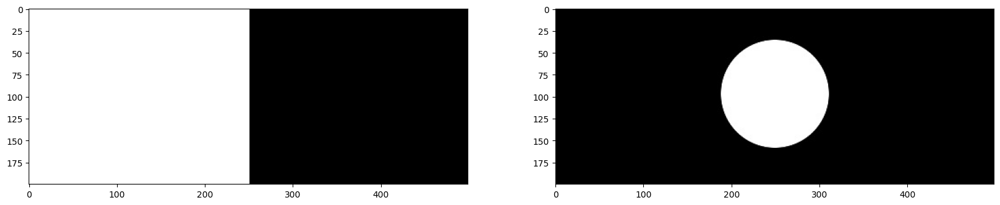

In [ ]:
img_rec = cv2.imread("rectangle.jpg", cv2.IMREAD_GRAYSCALE)

img_cir = cv2.imread("circle.jpg", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=[20, 5])
plt.subplot(121);plt.imshow(img_rec, cmap="gray")
plt.subplot(122);plt.imshow(img_cir, cmap="gray")
print(img_rec.shape)

### <font color="green">Operator Bitwise AND </font>

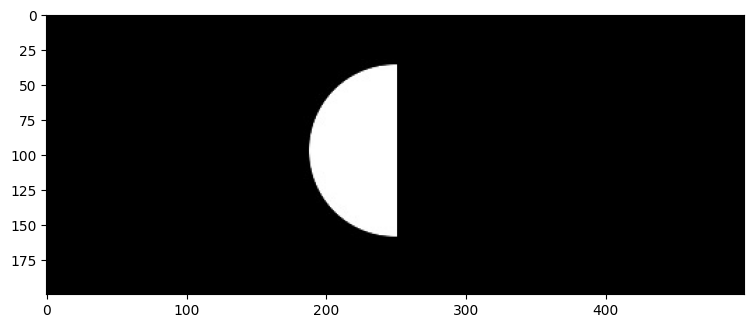

In [ ]:
result = cv2.bitwise_and(img_rec, img_cir, mask=None)
plt.imshow(result, cmap="gray")

### <font color="green">Operator Bitwise OR  </font>

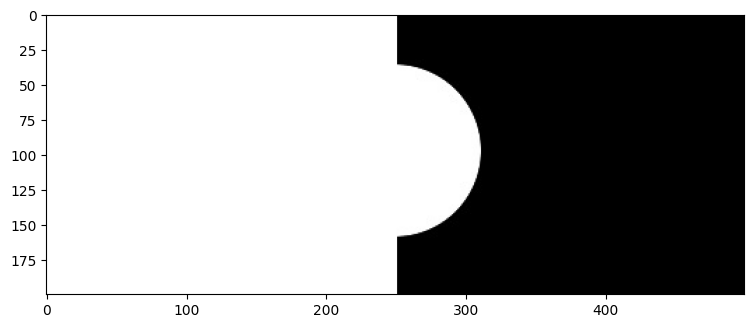

In [ ]:
result = cv2.bitwise_or(img_rec, img_cir, mask=None)
plt.imshow(result, cmap="gray")

### <font color="green">Operator Bitwise XOR </font>

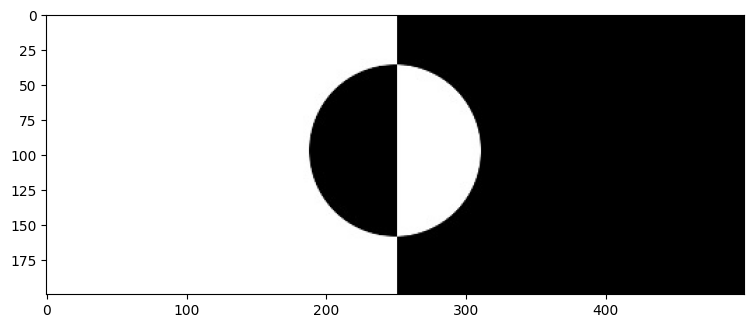

In [ ]:
result = cv2.bitwise_xor(img_rec, img_cir, mask=None)
plt.imshow(result, cmap="gray")

**LATIHAN**

Jalankan operasi-operasi manipulasi piksel (addition, subtraction, multiplication, dsb) menggunakan data citra low contrast yang tersedia di link berikut: https://www.talentica.com/wp-content/uploads/2017/09/y1-300x200.png